In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl
from scipy.stats import pearsonr, linregress
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from IPython.display import display




## Challenge

**Build a Weekly Sales Forecasting Model**:

-Develop and evaluate a machine learning model to forecast future weekly sales for each store-department combination, leveraging historical sales patterns and relevant predictive features to support retail sales planning.


## Phase 1: Data Preparation

In [2]:
path_dir = r"C:\Users\paolo\OneDrive\Desktop\Data Science Projects\predictive-model-retail-sales-forecast\data\raw"

stores = pd.read_csv(path_dir + r"\stores.csv")
sales = pd.read_csv(path_dir + r"\sales.csv")
features = pd.read_csv(path_dir + r"\features.csv")

## Inspecting dataset structure, granularity, primary keys
Notes: 
1. Each dataset connects to each other on store_id(primary key)
2. The `sales` table is the primary dataset, with each observation representing a unique Store × Department × Week combination

Next step is to merge datasets on `sales` which will make it easier to conduct the analsysis & build out the models; further reviewing & handling of any duplicates, missing values and/or outliers found before initial EDA

In [ ]:
# Structure Insepction + Key + Granularity

# Sales grain granularity -> unique store id by department per weekly date
sales.info() # sales - 156K rows | 5 columns | PK: store_id
display(sales.head(5))
print("\n")

# Features granularity -> unique store id by weekly date
features.info() # features - 7.8k rows | 14 columns | PK: store_id
display(features.head(5))
print("\n")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  object 
 3   weekly_sales  156000 non-null  float64
 4   is_holiday    156000 non-null  int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 6.0+ MB


,store_id,department,date,weekly_sales,is_holiday
0,1,1,2022-01-01,119075.96,1
1,1,2,2022-01-01,119107.85,1
2,1,3,2022-01-01,84369.88,1
3,1,4,2022-01-01,88445.24,1
4,1,5,2022-01-01,65159.85,1




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7800 entries, 0 to 7799
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   store_id      7800 non-null   int64  
 1   date          7800 non-null   object 
 2   temperature   7800 non-null   float64
 3   fuel_price    7800 non-null   float64
 4   markdown_1    7800 non-null   float64
 5   markdown_2    7800 non-null   float64
 6   markdown_3    7800 non-null   float64
 7   markdown_4    7800 non-null   float64
 8   markdown_5    7800 non-null   float64
 9   cpi           7800 non-null   float64
 10  unemployment  7800 non-null   float64
 11  is_holiday    7800 non-null   int64  
 12  holiday_name  900 non-null    object 
 13  season        7800 non-null   object 
dtypes: float64(9), int64(2), object(3)
memory usage: 853.3+ KB


,store_id,date,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday,holiday_name,season
0,1,2022-01-01,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2022-01-08,46.03,3.67,1356.75,2486.21,1427.01,983.27,2442.13,196.91,8.62,0,NaN,Winter
2,1,2022-01-15,25.96,5.46,3861.22,596.15,22.09,2854.11,3180.86,267.48,8.40,0,NaN,Winter
3,1,2022-01-22,25.92,3.58,579.35,2589.31,2493.19,1158.14,286.01,217.32,5.28,0,NaN,Winter
4,1,2022-01-29,78.37,4.41,4436.06,1416.64,478.38,2496.36,3423.53,247.35,8.40,0,NaN,Winter


In [ ]:
# Structure Insepction + Key
stores.info() # stores - 50 rows | 4 columns | PK: store_id
display(stores.head(5)) #


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   store_id    50 non-null     int64 
 1   store_type  50 non-null     object
 2   store_size  50 non-null     int64 
 3   region      50 non-null     object
dtypes: int64(2), object(2)
memory usage: 1.7+ KB


,store_id,store_type,store_size,region
0,1,A,213810,North
1,2,C,31639,East
2,3,B,102098,South
3,4,B,88289,North
4,5,A,218696,North


## Merging datasets and Handling Dataypes, Duplicates, Missing Values
Notes:
1. **Duplicates?** - No values found; removed duplicate variables (`is_holiday_x`, `is_holiday_y`)
2. **Missing Values?** - `holiday_name` contains missing values for non-holiday periods. These were retained as nulls since is_holiday already indicates whether a given week is a holiday (1) or non-holiday (0). No imputation was necessary.

In [71]:
retail_sales = sales.merge(
    stores,
    on="store_id",
    how="left"
).merge(
    features,
    on=["store_id", "date"],
    how="left"
)

retail_sales = pd.DataFrame(retail_sales)
retail_sales.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  object 
 3   weekly_sales  156000 non-null  float64
 4   is_holiday_x  156000 non-null  int64  
 5   store_type    156000 non-null  object 
 6   store_size    156000 non-null  int64  
 7   region        156000 non-null  object 
 8   temperature   156000 non-null  float64
 9   fuel_price    156000 non-null  float64
 10  markdown_1    156000 non-null  float64
 11  markdown_2    156000 non-null  float64
 12  markdown_3    156000 non-null  float64
 13  markdown_4    156000 non-null  float64
 14  markdown_5    156000 non-null  float64
 15  cpi           156000 non-null  float64
 16  unemployment  156000 non-null  float64
 17  is_holiday_y  156000 non-null  int64  
 18  holi

In [72]:
#drop duplicate columns
retail_sales.drop(columns=['is_holiday_y'], inplace=True) 

#convert `date` into to date format
retail_sales['date'] = pd.to_datetime(retail_sales['date'])

In [73]:
# Splitting Categorical & Numerical Variables
category_var = [
    'store_id',
    'store_type',
    'department',
    'holiday_name',
    'is_holiday_x',
    'region',
    'season'
]
# assign categorical data
retail_sales[category_var] = retail_sales[category_var].astype('category')

numerical_var =  [
    'weekly_sales',
    'store_size',
    'temperature',
    'fuel_price',
    'cpi',
    'unemployment',
    'markdown_1', 
    'markdown_2', 
    'markdown_3', 
    'markdown_4', 
    'markdown_5',
]

print("category variables:", category_var) #
print("numerical variables", numerical_var)

retail_sales.info()

category variables: ['store_id', 'store_type', 'department', 'holiday_name', 'is_holiday_x', 'region', 'season']
numerical variables ['weekly_sales', 'store_size', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'markdown_1', 'markdown_2', 'markdown_3', 'markdown_4', 'markdown_5']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 19 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store_id      156000 non-null  category      
 1   department    156000 non-null  category      
 2   date          156000 non-null  datetime64[ns]
 3   weekly_sales  156000 non-null  float64       
 4   is_holiday_x  156000 non-null  category      
 5   store_type    156000 non-null  category      
 6   store_size    156000 non-null  int64         
 7   region        156000 non-null  category      
 8   temperature   156000 non-null  float64       
 9   fuel_price    156000 non-null  float6

In [64]:
# Checking for Duplicates Values: 0 found
retail_sales.duplicated(
    subset=['store_id', 'department', 'date']
).sum()



np.int64(0)

In [65]:
# Checking for Missing Values: missing holiday names for 138K rows
pd.DataFrame({
    'missing_values': retail_sales.isnull().sum(),
    'missing_prop': (retail_sales.isnull().mean() * 100).round(2)
})

,missing_values,missing_prop
store_id,0,0.00
department,0,0.00
date,0,0.00
weekly_sales,0,0.00
is_holiday_x,0,0.00
store_type,0,0.00
store_size,0,0.00
region,0,0.00
temperature,0,0.00
fuel_price,0,0.00


## EDA

Goal: Understand the behaviour of target variable (`weekly_sales`) and the drivers that may explain its variation

## High-Level Data
Rationale:

Questions to Answer:
1. Are there signification variation in weekly across each observation?
2. Are there obvious growth and seasonal monthly/weekly pattern in sales?

In [66]:
#variance and central tendencies for weekly_sales
retail_sales['weekly_sales'].describe() 

# Mean > Median -- right-skewed; contains high-sales observations

count    156000.000000
mean      56503.488802
std       46717.490663
min         819.660000
25%       21255.962500
50%       43394.870000
75%       79604.107500
max      505958.730000
Name: weekly_sales, dtype: float64

**Finding #1:**  Weekly sales exhibit significant variation across Store × Department combinations, with a right-skewed distribution indicating a small number of exceptionally high-sales observations.

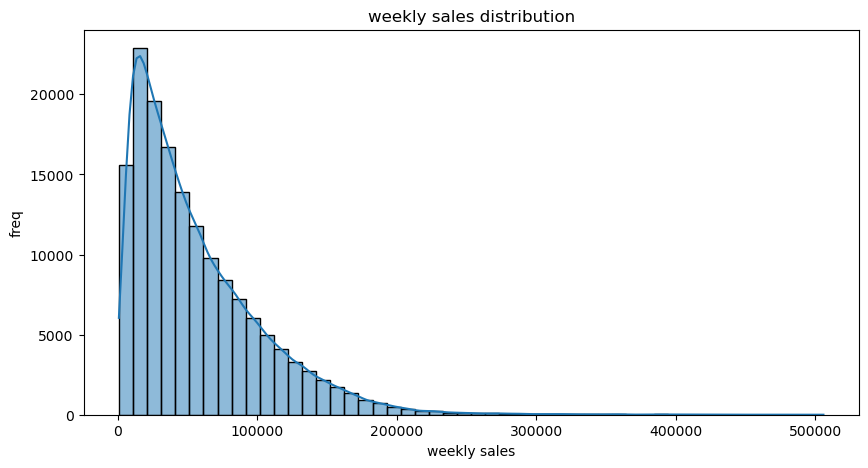

In [67]:
# weekly_sales distribution
plt.figure(figsize=(10,5))
sns.histplot(retail_sales['weekly_sales'], bins=50, kde=True)
plt.title('weekly sales distribution')
plt.xlabel('weekly sales')
plt.ylabel('freq')
plt.show()

# Long right-tail

In [ ]:
#sales time period
print("Min Date:", retail_sales['date'].min())
print("Max Date:", retail_sales['date'].max())

Min Date: 2022-01-01 00:00:00
Max Date: 2024-12-21 00:00:00


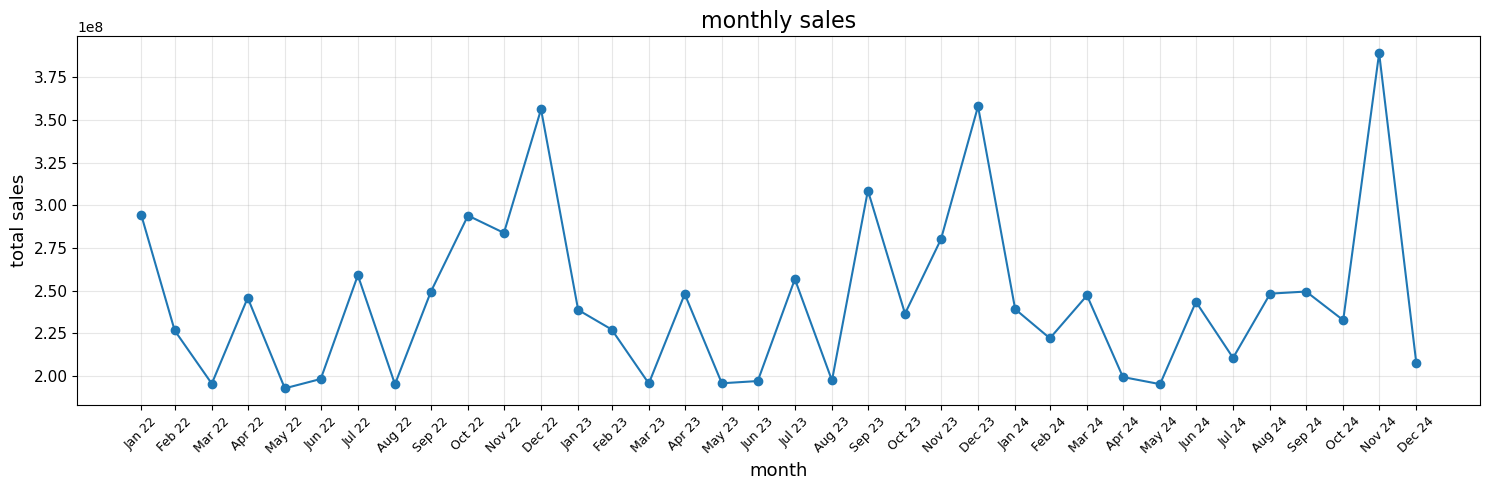

In [82]:
#monthly trend
monthly_trend = (
    retail_sales.set_index('date')['weekly_sales']
    .resample('ME')
    .sum()
)

plt.figure(figsize=(15, 5))
plt.plot(monthly_trend.index, monthly_trend.values, marker='o')

plt.title('monthly sales', fontsize=16)
plt.xlabel('month', fontsize=13)
plt.ylabel('total sales', fontsize=13)

plt.xticks(
    monthly_trend.index,
    monthly_trend.index.strftime('%b %y'),
    rotation=45,
    fontsize=9
)

plt.yticks(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Correlation Analysis
**Rationale:** For this particular modeling objective, it is important to determine if certain store characteristics drive `weekly_sales` ; characteristics like `store_size`, `region`, `store_type` & `department` are explored here. As these will determine which potential features to include in the engineering of the model specifically for store attributes

Questions to Answer:
1. Is there a correlation to a store's size and it's produced weekly sales?
2. Is there a correlation between the average weekly sales of the same department across different stores?
3. Do other variables like store type and region have a pattern affecting sales?

In [99]:
#checking how many unique store x combinations there are
print("unique stores:", retail_sales['store_id'].drop_duplicates().shape[0])
print("unique departments:", retail_sales['department'].drop_duplicates().shape[0])
print("store x department combinations:", retail_sales[['store_id', 'department']].drop_duplicates().shape[0])

unique stores: 50
unique departments: 20
store x department combinations: 1000


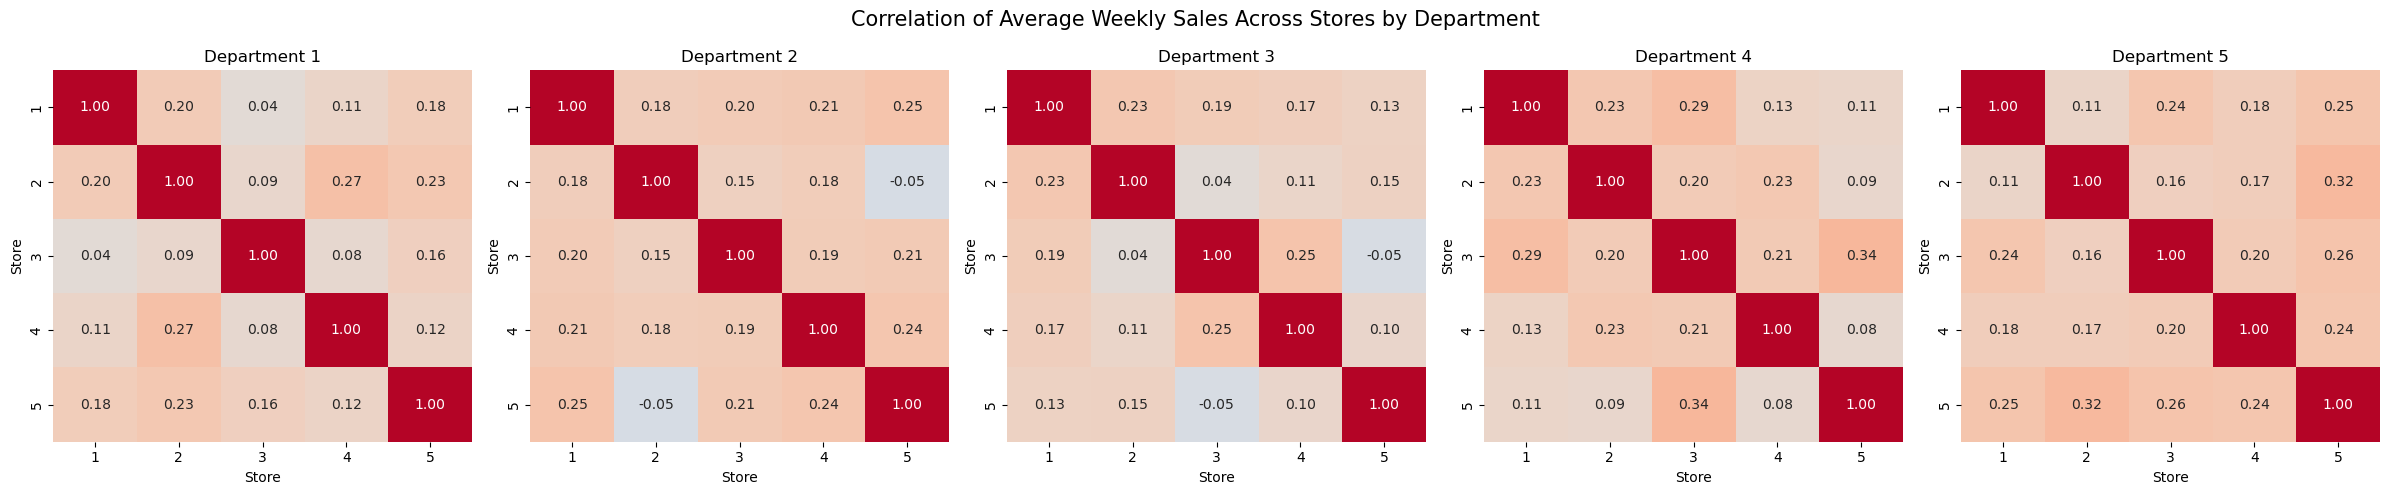

In [ ]:
#investigating correlation for department and avg. weekly sales
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for dept, ax in zip([1, 2, 3, 4, 5], axes):
    sales_pivot = (
        retail_sales[
            (retail_sales['department'] == dept) &
            (retail_sales['store_id'].isin([1, 2, 3, 4, 5]))
        ]
        .groupby(['date', 'store_id'], observed=True)['weekly_sales']
        .mean()
        .unstack()
    )

    store_corr = sales_pivot.corr()

    sns.heatmap(
        store_corr,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax,
        cbar=False
    )

    ax.set_title(f'Department {dept}')

plt.suptitle(
    'Correlation of Average Weekly Sales Across Stores by Department',
    fontsize=15
)

plt.tight_layout()
plt.show()
#Results: most store x department combinations exhibit positive correlations in average weekly sales across stores, suggesting that sales generally move in the same direction.
#However, the degree of correlation varies across stores and departments, with most relationships being relatively weak (below 0.5).

C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\3443008523.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('store_id')
C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\3443008523.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


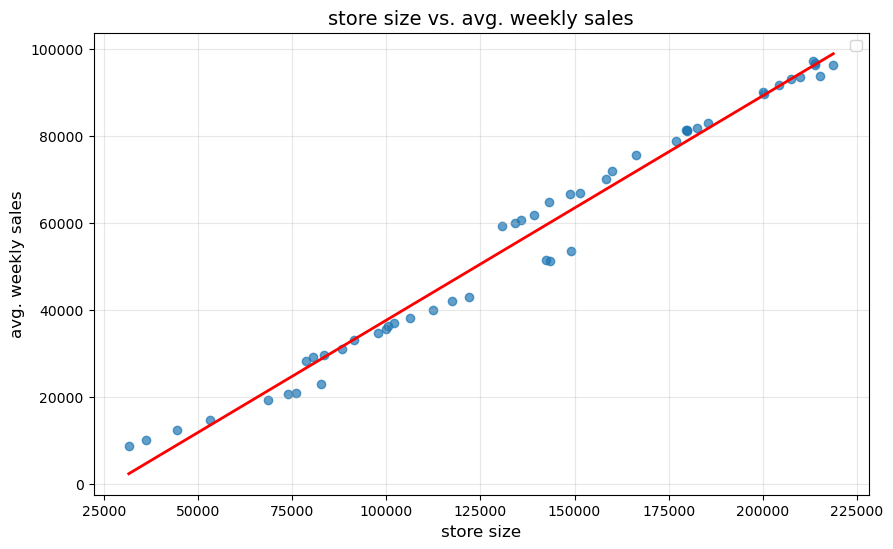

                  store_size  avg_weekly_sales
store_size          1.000000          0.990793
avg_weekly_sales    0.990793          1.000000


In [ ]:
#check if each store has different store size
store_size = (
    retail_sales
    .groupby('store_id')
    .agg(
        store_size=('store_size', 'first'),
        avg_weekly_sales=('weekly_sales', 'mean')
    )
    .reset_index()
    .sort_values('store_size', ascending=False)
)  #Confirmed


#checking for linear relationship between store size and avg. weekly sales
x = store_size['store_size']
y = store_size['avg_weekly_sales']

m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.7)
plt.plot(x, m*x + b, color='red', linewidth=2)
plt.title('store size vs. avg. weekly sales', fontsize=14)
plt.xlabel('store size', fontsize=12)
plt.ylabel('avg. weekly sales', fontsize=12)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(store_size[['store_size', 'avg_weekly_sales']].corr())

#Result: confirmed initial assumption that there is a extremely strong positive correlation of store size vs. weekly sales (correlation coefficient: 0.991)

In [ ]:
retail_sales.groupby(
    ['store_type', 'store_id'],
    observed=True
).agg(
    store_size=('store_size', 'first'),
    region=('region', 'first'),
    avg_weekly_sales=('weekly_sales', 'mean')
).reset_index().sort_values(
    ['store_type', 'store_size'],
    ascending=[True, False]
)

#Results: Store Type A has the largest store sizes on average, followed by Store Type B and Store Type C (A > B > C); no obvious pattern except for store_size

,store_type,store_id,store_size,region,avg_weekly_sales
1,A,5,218696,North,96174.319548
4,A,11,215181,West,93703.213080
21,A,41,213886,South,96734.567692
0,A,1,213810,North,96123.396051
16,A,32,213320,East,97186.874824
18,A,37,209840,South,93389.211147
2,A,6,207397,West,92986.518862
24,A,47,204341,East,91591.884330
12,A,23,200284,North,89627.896346
19,A,38,200010,South,89983.776311


C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\2016068752.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('department')['weekly_sales']


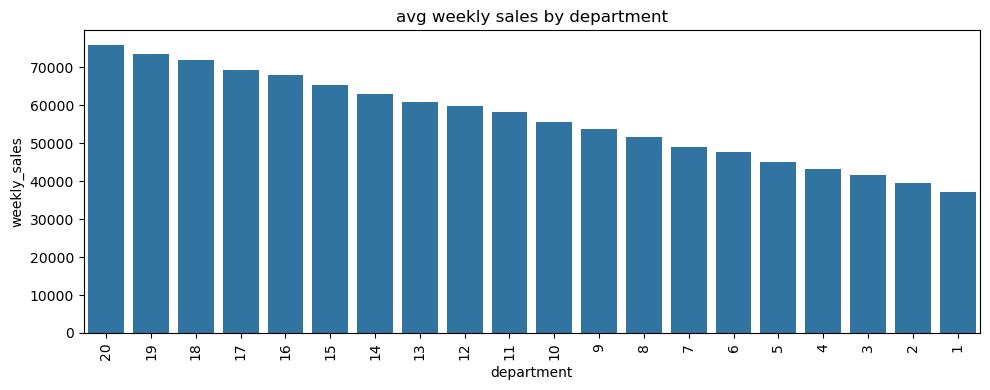

In [ ]:
department_sales = (
    retail_sales
    .groupby('department')['weekly_sales']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=department_sales,
    x='department',
    y='weekly_sales',
    order=department_sales['department']
)
plt.title('avg weekly sales by department')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#Results: larger department id's  follow higher avg. weekly sales and are linear in its relationship

## Historical Sales Pattern Analysis
**Rationale:** Since the objective is to forecast weekly sales for each Store × Department combination over the next four weeks, understanding historical sales behavior is essential to determine whether past performance and recent sales trends can provide useful signals for future predictions

Questions to Answer:
1. How strongly are current weekly sales associated with previous weeks' sales?
2. What about rolling mean averages?
3. Are historical sales patterns consistent across Store × Department combinations?

In [ ]:
#analyzing historical lag sales performance at a certain point in time
retail_sales['sales_lag_1'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(1)
)

retail_sales['sales_lag_4'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(4)
)

retail_sales['sales_lag_8'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(8)
)

retail_sales['sales_lag_12'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(12)
)

retail_sales['sales_lag_16'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(16)
)

retail_sales['sales_lag_52'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(52)
)

# exploring correlation vs. today's sales
retail_sales[
    ['weekly_sales', 'sales_lag_1', 'sales_lag_4',
     'sales_lag_8', 'sales_lag_12', 'sales_lag_16',
     'sales_lag_52']
].corr()

#Result: weekly sales lags provide moderation correlation strength vs. current weekly sales, with sales_lag_52 providing the highest positive correlation. 
#Indicating a strong YoY sales pattern as a strong signal for prediction

C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\309540467.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(1)
C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\309540467.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  retail_sales.groupby(['store_id', 'department'])['weekly_sales'].shift(4)
C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\309540467.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observ

,weekly_sales,sales_lag_1,sales_lag_4,sales_lag_8,sales_lag_12,sales_lag_16,sales_lag_52
weekly_sales,1.000000,0.465830,0.462519,0.440006,0.444568,0.419896,0.498750
sales_lag_1,0.465830,1.000000,0.445941,0.440576,0.437206,0.419819,0.453600
sales_lag_4,0.462519,0.445941,1.000000,0.461457,0.441774,0.444126,0.462066
sales_lag_8,0.440006,0.440576,0.461457,1.000000,0.463256,0.443140,0.441405
sales_lag_12,0.444568,0.437206,0.441774,0.463256,1.000000,0.463220,0.433707
sales_lag_16,0.419896,0.419819,0.444126,0.443140,0.463220,1.000000,0.417527
sales_lag_52,0.498750,0.453600,0.462066,0.441405,0.433707,0.417527,1.000000


In [ ]:
#analyzing rolling mean lags 
retail_sales['sales_rolling_mean_4'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales']
    .transform(lambda x: x.shift(1).rolling(4).mean())
)

retail_sales['sales_rolling_mean_8'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales']
    .transform(lambda x: x.shift(1).rolling(8).mean())
)

retail_sales['sales_rolling_mean_12'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales']
    .transform(lambda x: x.shift(1).rolling(12).mean())
)

retail_sales['sales_rolling_mean_16'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales']
    .transform(lambda x: x.shift(1).rolling(16).mean())
)

retail_sales['sales_rolling_mean_52'] = (
    retail_sales.groupby(['store_id', 'department'])['weekly_sales']
    .transform(lambda x: x.shift(1).rolling(52).mean())
)

retail_sales[
    ['weekly_sales', 'sales_rolling_mean_4', 'sales_rolling_mean_8',
     'sales_rolling_mean_12', 'sales_rolling_mean_16',
     'sales_rolling_mean_52']
].corr()

#Result: weekly sales lags provide moderation correlation strength vs. current weekly sales, with sales_lag_52 providing the highest positive correlation. 
#Indicating a strong YoY sales pattern as a strong signal for prediction

C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\1703168191.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  retail_sales.groupby(['store_id', 'department'])['weekly_sales']
C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\1703168191.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  retail_sales.groupby(['store_id', 'department'])['weekly_sales']
C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\1703168191.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adop

,weekly_sales,sales_rolling_mean_4,sales_rolling_mean_8,sales_rolling_mean_12,sales_rolling_mean_16,sales_rolling_mean_52
weekly_sales,1.000000,0.591361,0.623132,0.633151,0.632559,0.642544
sales_rolling_mean_4,0.591361,1.000000,0.940962,0.914974,0.899123,0.856333
sales_rolling_mean_8,0.623132,0.940962,1.000000,0.977147,0.962038,0.914912
sales_rolling_mean_12,0.633151,0.914974,0.977147,1.000000,0.987558,0.939299
sales_rolling_mean_16,0.632559,0.899123,0.962038,0.987558,1.000000,0.953938
sales_rolling_mean_52,0.642544,0.856333,0.914912,0.939299,0.953938,1.000000


C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\3513174716.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: pd.Series({


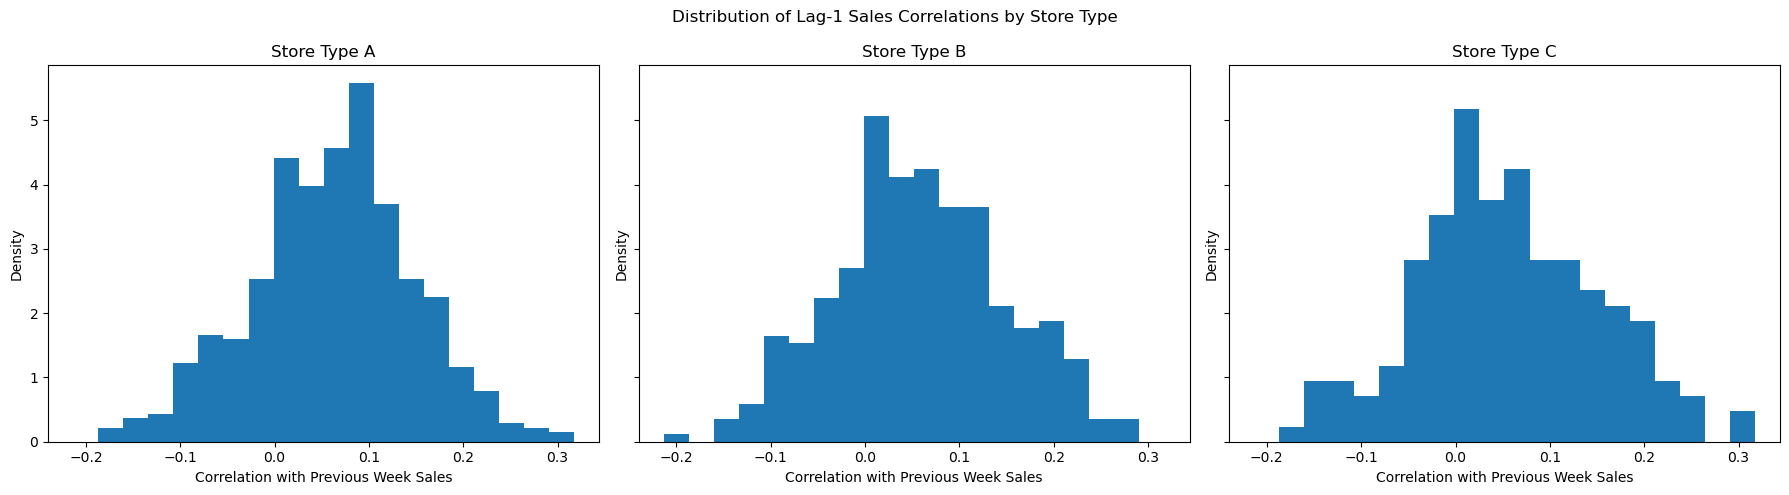

In [ ]:
#analyzing if there's a pattern in the correlation of historical weekly sales across different store x department combinations
historical_corr = (
    retail_sales.groupby(['store_id', 'department'], observed=True)
    .apply(lambda x: pd.Series({
        'store_type': x['store_type'].iloc[0],
        'lag_1_corr': x['weekly_sales'].corr(x['sales_lag_1'])
    }))
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

bins = np.histogram_bin_edges(
    historical_corr['lag_1_corr'].dropna(),
    bins=20
)

for ax, store_type in zip(axes, ['A', 'B', 'C']):
    data = historical_corr.loc[
        historical_corr['store_type'] == store_type,
        'lag_1_corr'
    ].dropna()

    ax.hist(data, bins=bins, density=True)

    ax.set_title(f'Store Type {store_type}')
    ax.set_xlabel('Correlation with Previous Week Sales')
    ax.set_ylabel('Density')

plt.suptitle('Distribution of Lag-1 Sales Correlations by Store Type')
plt.tight_layout()
plt.show()

## Calendar/Seasonality Effects 

In [188]:
retail_sales.groupby('is_holiday_x')['weekly_sales'].mean().reset_index()

C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\3458190061.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  retail_sales.groupby('is_holiday_x')['weekly_sales'].mean().reset_index()


,is_holiday_x,weekly_sales
0,0,52852.575328
1,1,84493.825439


In [213]:
holiday_analysis = (
    retail_sales
    .groupby(
        ['store_type', 'store_id', 'department', 'is_holiday_x'],
        observed=True
    )
    ['weekly_sales']
    .mean()
    .reset_index()
)

sample_combinations = (
    holiday_analysis[['store_type', 'store_id', 'department']]
    .drop_duplicates()
    .groupby('store_type', group_keys=False)
    .sample(n=3)
)

holiday_sample = holiday_analysis.merge(
    sample_combinations,
    on=['store_type', 'store_id', 'department']
)

holiday_pivot = (
    holiday_sample.pivot(
        index=['store_type', 'store_id', 'department'],
        columns='is_holiday_x',
        values='weekly_sales'
    )
    .rename(columns={
        False: 'Non-Holiday Sales',
        True: 'Holiday Sales'
    })
)

holiday_pivot['Difference (%)'] = (
    (holiday_pivot['Holiday Sales'] - holiday_pivot['Non-Holiday Sales'])
    / holiday_pivot['Non-Holiday Sales'] * 100
)

holiday_pivot.round(2)

C:\Users\paolo\AppData\Local\Temp\ipykernel_125244\3996061153.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('store_type', group_keys=False)


is_holiday_x                    Non-Holiday Sales  Holiday Sales  \
store_type store_id department                                     
A          6        1                    59517.21       81424.35   
           16       13                   73521.64       98372.13   
           32       4                    68330.94      126150.43   
B          18       16                   35569.18       45517.17   
           28       12                   36961.74       45021.05   
           29       16                   32426.91       59162.16   
C          8        4                     7351.94       13824.64   
                    10                    8454.38       15360.12   
           36       7                    17230.64       27318.31   

is_holiday_x                    Difference (%)  
store_type store_id department                  
A          6        1                    36.81  
           16       13                   33.80  
           32       4                    84.62  
B          18       16                   27.97  
           28       12                   21.80  
           29       16                   82.45  
C          8        4                    88.04  
                    10                   81.68  
           36       7                    58.54

## Inferences on Sales

In [10]:
## Inferences on Sales

# Historical + Seasonal Data Signals
# 1. Does historical sales pattern help predict future sales?
#    Potential features: lag_1, lag_2, lag_4, lag_8, lag_16, is_holiday, week_of_year, week_of_month, month_

# Store Characteritic Signals (Model B
# 2. Does sales differ across stores, department, store types, store_size?
#    Potential features: store_id, department_id, store_types, store_size
#    Feature: Include

# Economic Indicators Signals
# 3. Are economic indicators associated with weekly sales?
#    Potential features: fuel_price, unemployment, cpi


## Targetted EDA & Hypotheses on Inferences

## Historical Sales Lag
Historical sales may help predict future weekly sales. Lag features (e.g., 1, 2, 4, 8, 12, and 16 weeks prior) capture sales at specific intervals, while rolling means capture recent sales trends by averaging sales over a defined window.

## Seasonality and Holiday Effects
Weekly sales exhibit a recurring seasonal pattern, rising sharply in September and peaking in November–December before declining (Figure A). Holiday weeks also show differences in average weekly sales compared with non-holiday weeks (Figures B).

This seasonal pattern appears consistent across stores (Figures D and E), suggesting that `month` and `is_holiday` are promising candidate predictors for capturing seasonal fluctuations in weekly sales.

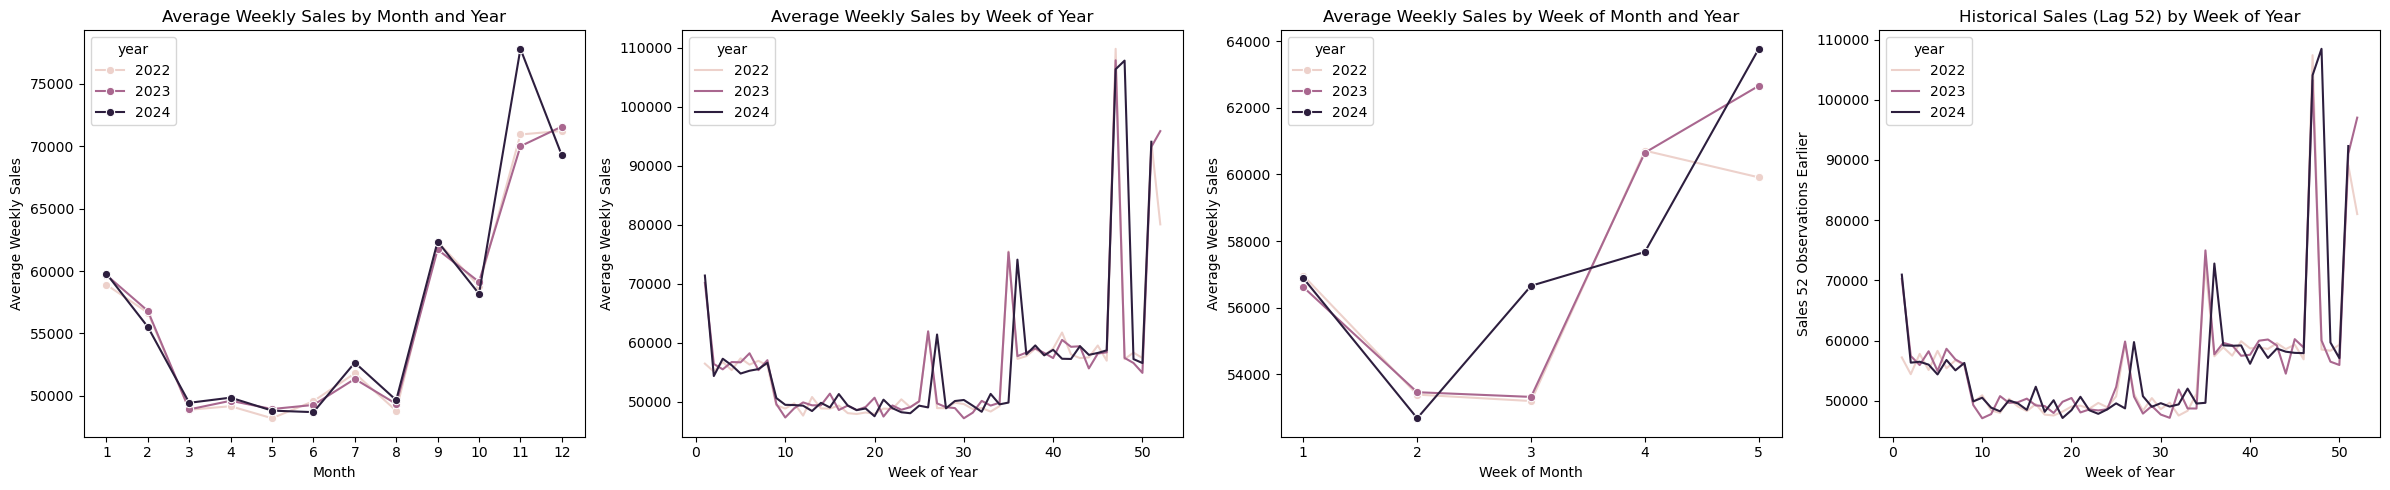

In [11]:
retail_sales["date"] = pd.to_datetime(retail_sales["date"])
retail_sales["month"] = retail_sales["date"].dt.month
retail_sales["year"] = retail_sales["date"].dt.year
retail_sales["week_of_year"] = retail_sales["date"].dt.isocalendar().week.astype(int)
retail_sales["week_of_month"] = ((retail_sales["date"].dt.day - 1) // 7) + 1

# Create lag 52
retail_sales = retail_sales.sort_values("date").copy()
retail_sales["lag_52"] = retail_sales["weekly_sales"].shift(52)

# Aggregate sales by year and calendar feature
monthly_sales = retail_sales.groupby(["year", "month"])["weekly_sales"].mean().reset_index()
weekly_year_sales = retail_sales.groupby(["year", "week_of_year"])["weekly_sales"].mean().reset_index()
weekly_month_sales = retail_sales.groupby(["year", "week_of_month"])["weekly_sales"].mean().reset_index()
lag52_sales = retail_sales.dropna(subset=["lag_52"]).groupby(["year", "week_of_year"])["lag_52"].mean().reset_index()

fig, axes = plt.subplots(1, 4, figsize=(24, 5))

# Figure A: Month, separate line per year
sns.lineplot(data=monthly_sales, x="month", y="weekly_sales", hue="year", marker="o", ax=axes[0])
axes[0].set_title("Average Weekly Sales by Month and Year")
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Average Weekly Sales")

# Figure B: Week of year, separate line per year
sns.lineplot(data=weekly_year_sales, x="week_of_year", y="weekly_sales", hue="year", ax=axes[1])
axes[1].set_title("Average Weekly Sales by Week of Year")
axes[1].set_xlabel("Week of Year")
axes[1].set_ylabel("Average Weekly Sales")

# Figure C: Week of month, separate line per year
sns.lineplot(data=weekly_month_sales, x="week_of_month", y="weekly_sales", hue="year", marker="o", ax=axes[2])
axes[2].set_title("Average Weekly Sales by Week of Month and Year")
axes[2].set_xticks([1, 2, 3, 4, 5])
axes[2].set_xlabel("Week of Month")
axes[2].set_ylabel("Average Weekly Sales")

# Figure D: Lag 52, separate line per year
sns.lineplot(data=lag52_sales, x="week_of_year", y="lag_52", hue="year", ax=axes[3])
axes[3].set_title("Historical Sales (Lag 52) by Week of Year")
axes[3].set_xlabel("Week of Year")
axes[3].set_ylabel("Sales 52 Observations Earlier")

plt.tight_layout()
plt.show()

## Candidate Features: Month, week_of_year, lag_52
## Rationale: Investigate recurring seasonal patterns and historical sales from approximately one year earlier.

In [12]:
retail_sales["month"] = retail_sales["date"].dt.month

holiday_monthly_sales = retail_sales.groupby(
    ["month", "is_holiday_x"]
)["weekly_sales"].mean().unstack()

holiday_monthly_sales.columns = ["Non-Holiday", "Holiday"]

holiday_monthly_sales["Holiday Growth %"] = (
    (holiday_monthly_sales["Holiday"] - holiday_monthly_sales["Non-Holiday"])
    / holiday_monthly_sales["Non-Holiday"]
) * 100

holiday_monthly_sales.round(2)

,Non-Holiday,Holiday,Holiday Growth %
month,,,
1,55989.72,70809.51,26.47
2,56327.29,NaN,NaN
3,49096.70,NaN,NaN
4,49509.00,NaN,NaN
5,48642.59,NaN,NaN
6,49130.17,NaN,NaN
7,49199.02,61704.27,25.42
8,49289.19,NaN,NaN
9,58257.84,74964.67,28.68


## Historical data across 50 stores shows a very strong positive relationship between store size and average weekly sales (Pearson r = 0.991, R² = 0.982, p < 0.001). This supports including `store_size` as a candidate predictive feature for weekly sales forecasting.

Number of stores: 50
Pearson correlation: 0.9908
P-value: 0.000000
R-squared: 0.9817
Slope: 0.5157


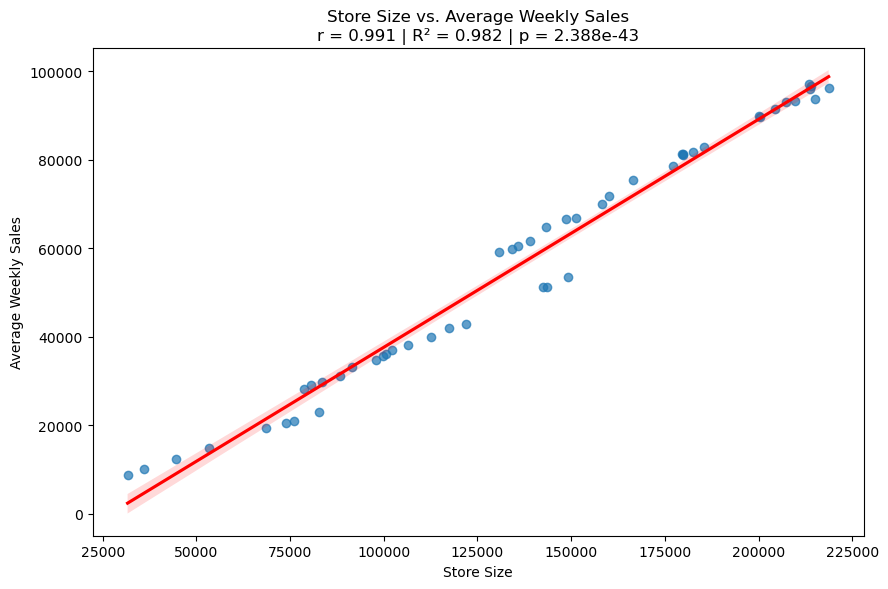

In [13]:
# Store Characteritic Signals
# 2. Does sales differ across stores, department, store types, store_size?
#    Potential features: store_id, department_id, store_types, store_size

# 1. Each observation represents one store
store_sales = (
    retail_sales.groupby("store_id", as_index=False)
    .agg(
        store_size=("store_size", "first"),
        avg_weekly_sales=("weekly_sales", "mean")
    )
    .dropna(subset=["store_size", "avg_weekly_sales"])
)

# 2. Measure correlation and fit linear regression
x = store_sales["store_size"]
y = store_sales["avg_weekly_sales"]

r, p_value = pearsonr(x, y)
regression = linregress(x, y)

print(f"Number of stores: {len(store_sales)}")
print(f"Pearson correlation: {r:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"R-squared: {regression.rvalue**2:.4f}")
print(f"Slope: {regression.slope:.4f}")

# 3. Visualize the relationship
plt.figure(figsize=(9, 6))

sns.regplot(
    data=store_sales,
    x="store_size",
    y="avg_weekly_sales",
    ci=95,
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title(
    f"Store Size vs. Average Weekly Sales\n"
    f"r = {r:.3f} | R² = {regression.rvalue**2:.3f} | p = {p_value:.4g}"
)
plt.xlabel("Store Size")
plt.ylabel("Average Weekly Sales")
plt.tight_layout()
plt.show()

## Store types with higher average weekly sales also tend to have larger average store sizes. This suggests that store type may serve as a strong candidate feature for predicting weekly sales, potentially capturing differences in store scale and sales performance.

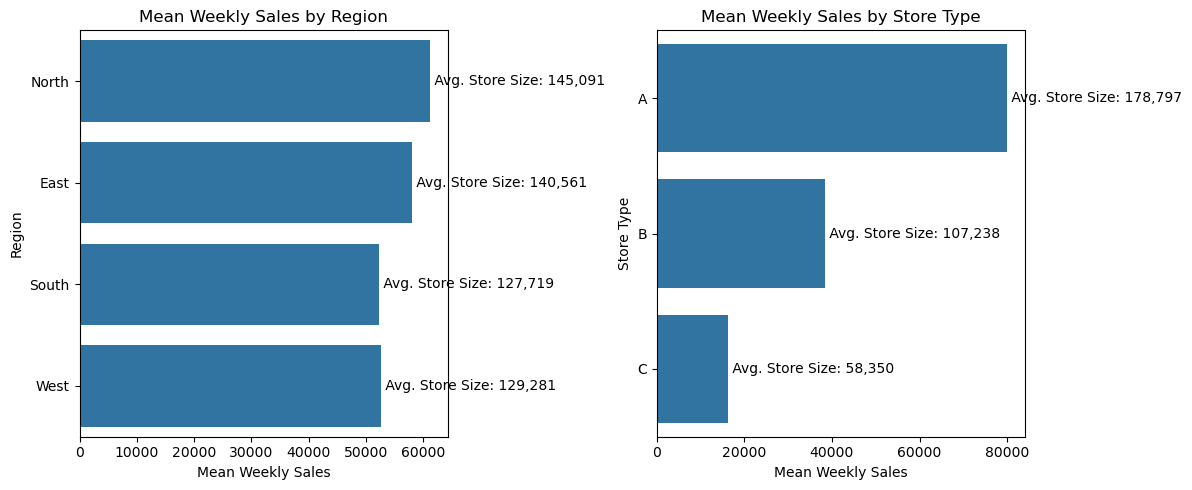

In [14]:

# Calculate average store size by region and store type
avg_size_region = retail_sales.groupby("region")["store_size"].mean().to_dict()
avg_size_type = retail_sales.groupby("store_type")["store_size"].mean().to_dict()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Mean Weekly Sales by Region
sns.barplot(
    data=retail_sales, x="weekly_sales", y="region",
    errorbar=None, ax=axes[0]
)
axes[0].set_title("Mean Weekly Sales by Region")
axes[0].set_xlabel("Mean Weekly Sales")
axes[0].set_ylabel("Region")

for i, region in enumerate(axes[0].get_yticklabels()):
    axes[0].text(
        axes[0].patches[i].get_width(),
        i,
        f" Avg. Store Size: {avg_size_region[region.get_text()]:,.0f}",
        va="center"
    )

# Mean Weekly Sales by Store Type
sns.barplot(
    data=retail_sales, x="weekly_sales", y="store_type",
    errorbar=None, ax=axes[1]
)
axes[1].set_title("Mean Weekly Sales by Store Type")
axes[1].set_xlabel("Mean Weekly Sales")
axes[1].set_ylabel("Store Type")

for i, store_type in enumerate(axes[1].get_yticklabels()):
    axes[1].text(
        axes[1].patches[i].get_width(),
        i,
        f" Avg. Store Size: {avg_size_type[store_type.get_text()]:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()


## Economic indicators (`fuel_price`, `unemployment`, `cpi`) show near-zero Pearson correlations with weekly sales across all stores combined, indicating little to no linear relationship. However, they may still provide predictive value when combined with other features, so they will be retained as candidate features for model evaluation.

In [15]:
# Economic Indicators Signals
# 4. Are economic indicators associated with weekly sales?
#    Potential features: fuel_price, unemployment, cpi

# Economic Indicators vs Weekly Sales

econ_indicators = ["fuel_price", "unemployment", "cpi"]

for indicator in econ_indicators:
    correlation = retail_sales[indicator].corr(retail_sales["weekly_sales"])
    print(f"{indicator}: {correlation:.3f}")

fuel_price: -0.002
unemployment: -0.007
cpi: -0.002


## Feature Engineering

In [16]:

# ==========================================
# 1. PREPARE DATASET
# ==========================================
retail_sales["date"] = pd.to_datetime(retail_sales["date"])

model_data = retail_sales.sort_values(
    ["store_id", "department", "date"]
).copy()


# ==========================================
# 2. HISTORICAL SALES FEATURES
# ==========================================

# Lag features
lag_windows = [1, 2, 4, 8]

for lag in lag_windows:
    model_data[f"lag_{lag}"] = (
        model_data.groupby(["store_id", "department"])["weekly_sales"]
        .shift(lag)
    )

# Rolling statistics
rolling_windows = [2, 4, 8]

for window in rolling_windows:
    sales_history = model_data.groupby(
        ["store_id", "department"]
    )["weekly_sales"]

    model_data[f"rolling_mean_{window}"] = (
        sales_history.transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

    model_data[f"rolling_std_{window}"] = (
        sales_history.transform(
            lambda x: x.shift(1).rolling(window).std()
        )
    )


# ==========================================
# 3. SEASONALITY & CALENDAR FEATURES
# ==========================================

model_data["month"] = model_data["date"].dt.month

model_data["week_of_year"] = (
    model_data["date"].dt.isocalendar().week.astype(int)
)


# ==========================================
# 4. DEFINE MODEL A FEATURES
# ==========================================

features_A = [
    # Historical sales
    "lag_1", "lag_2", "lag_4", "lag_8",
    "rolling_mean_2", "rolling_mean_4", "rolling_mean_8",
    "rolling_std_2", "rolling_std_4", "rolling_std_8",

    # Seasonality and calendar
    "month",
    "week_of_year",
    "is_holiday_x"
]

target = "weekly_sales"

print("Model A features:", features_A)
print("\nNumber of features:", len(features_A))
print("\nDataset shape:", model_data.shape)

model_data[["date", target] + features_A].head(20)


Model A features: ['lag_1', 'lag_2', 'lag_4', 'lag_8', 'rolling_mean_2', 'rolling_mean_4', 'rolling_mean_8', 'rolling_std_2', 'rolling_std_4', 'rolling_std_8', 'month', 'week_of_year', 'is_holiday_x']

Number of features: 13

Dataset shape: (156000, 35)


,date,weekly_sales,lag_1,lag_2,lag_4,lag_8,rolling_mean_2,rolling_mean_4,rolling_mean_8,rolling_std_2,rolling_std_4,rolling_std_8,month,week_of_year,is_holiday_x
0,2022-01-01,119075.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,52,1
20,2022-01-08,35525.05,119075.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0
40,2022-01-15,14847.56,35525.05,119075.96,NaN,NaN,77300.505,NaN,NaN,59079.415035,NaN,NaN,1,2,0
60,2022-01-22,45254.57,14847.56,35525.05,NaN,NaN,25186.305,NaN,NaN,14621.193397,NaN,NaN,1,3,0
80,2022-01-29,15166.69,45254.57,14847.56,119075.96,NaN,30051.065,53675.7850,NaN,21501.002967,45406.240356,NaN,1,4,0
100,2022-02-05,15601.13,15166.69,45254.57,35525.05,NaN,30210.630,27698.4675,NaN,21275.343980,15184.020103,NaN,2,5,0
120,2022-02-12,52743.22,15601.13,15166.69,14847.56,NaN,15383.910,22717.4875,NaN,307.195470,15027.895544,NaN,2,6,0
140,2022-02-19,38995.95,52743.22,15601.13,45254.57,NaN,34172.175,32191.4025,NaN,26263.423706,19647.743933,NaN,2,7,0
160,2022-02-26,62899.98,38995.95,52743.22,15166.69,119075.96,45869.585,30626.7475,42151.26625,9720.787840,18474.888051,34375.366418,2,8,0
180,2022-03-05,56896.47,62899.98,38995.95,15601.13,35525.05,50947.965,42560.0700,35129.26875,16902.701711,20468.641707,18478.921340,3,9,0


In [17]:
# Remove rows only when required features or target are missing
model_data = model_data.dropna(subset=features_A + ["weekly_sales"])

print("Remaining dates:", model_data["date"].nunique())
print("Remaining rows:", len(model_data))

Remaining dates: 148
Remaining rows: 148000


In [19]:
dates = sorted(model_data["date"].unique())

train_dates, temp_dates = train_test_split(
    dates, test_size=0.30, shuffle=False
)

val_dates, test_dates = train_test_split(
    temp_dates, test_size=0.50, shuffle=False
)

train_data = model_data[model_data["date"].isin(train_dates)]
val_data = model_data[model_data["date"].isin(val_dates)]
test_data = model_data[model_data["date"].isin(test_dates)]

print("Training dates:", train_data["date"].nunique())
print("Validation dates:", val_data["date"].nunique())
print("Test dates:", test_data["date"].nunique())

Training dates: 103
Validation dates: 22
Test dates: 23


## Model A: Linear Regression - Historical + Seasonality Features 

"lag_1", "lag_2", "lag_4", "lag_8", "lag_12", "lag_16",
"rolling_mean_4", "rolling_mean_8", "rolling_mean_12",
"rolling_std_4", "rolling_std_8", "rolling_std_12",
"expanding_mean"

In [20]:
# Training data
X_train = train_data[features_A]
y_train = train_data["weekly_sales"]

# Validation data
X_val = val_data[features_A]
y_val = val_data["weekly_sales"]

# Test data
X_test = test_data[features_A]
y_test = test_data["weekly_sales"]

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_val)

## Baseline Results

- valuating MAE and RMSE for "lag_1" feature only

Global Baseline MAE: 29060.31
Global Baseline RMSE: 40586.4
Global Baseline MAPE: 93.2 %


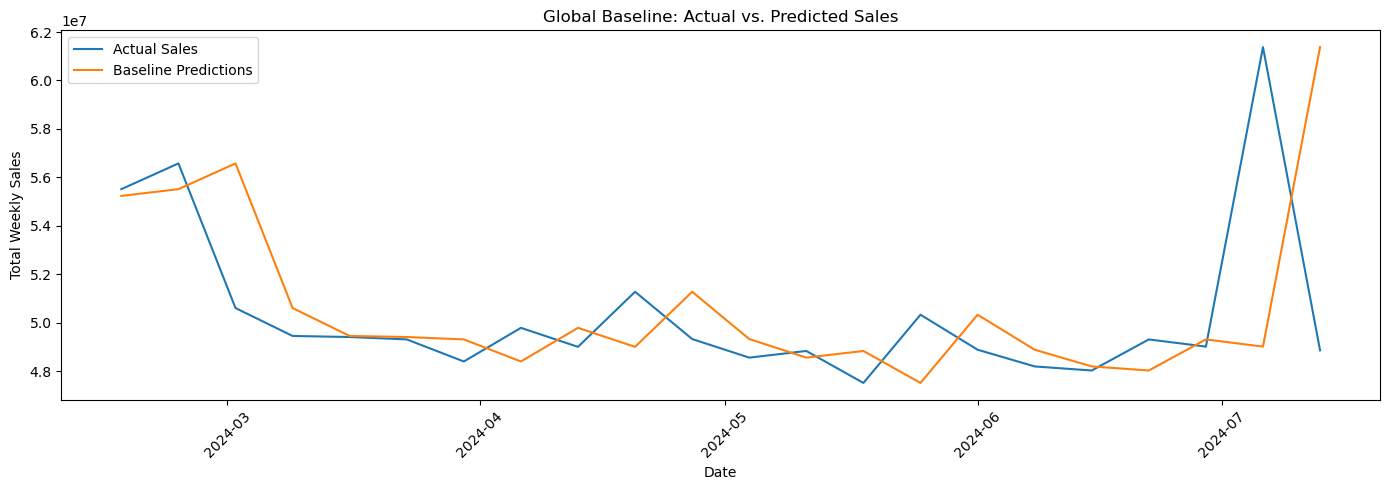

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict using previous week's sales
y_pred_baseline = X_val["lag_1"]

# Evaluate baseline globally
baseline_mae = mean_absolute_error(y_val, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_val, y_pred_baseline))

baseline_mape = (
    np.abs((y_val - y_pred_baseline) / y_val.replace(0, np.nan))
).mean() * 100

print("Global Baseline MAE:", round(baseline_mae, 2))
print("Global Baseline RMSE:", round(baseline_rmse, 2))
print("Global Baseline MAPE:", round(baseline_mape, 2), "%")

# Combine actual and predicted sales
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": y_pred_baseline.to_numpy()
})

# Aggregate sales across all stores and departments by date
global_daily_sales = global_results.groupby("date")[
    ["actual", "predicted"]
].sum().reset_index()

# Plot global actual vs. predicted sales
plt.figure(figsize=(14, 5))
plt.plot(global_daily_sales["date"], global_daily_sales["actual"], label="Actual Sales")
plt.plot(global_daily_sales["date"], global_daily_sales["predicted"], label="Baseline Predictions")

plt.title("Global Baseline: Actual vs. Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Model A  Results

- Evaluating MAE and RMSE for all Model A features
- Evaluating Predicted vs. Actual Results on 1 store + department combination

Global Validation MAE: 22281.05
Global Validation RMSE: 29639.1
Global Validation MAPE: 77.91 %


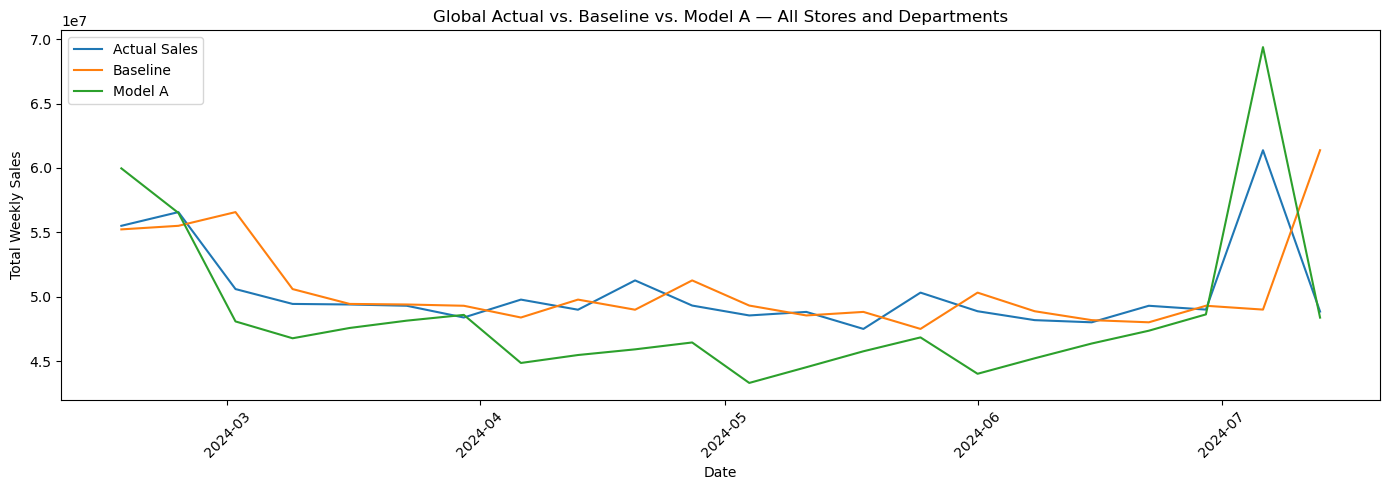

In [22]:
# Evaluate model globally
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
global_mape = (
    np.abs((y_val - y_pred) / y_val.replace(0, np.nan))
).mean() * 100

print("Global Validation MAE:", round(mae, 2))
print("Global Validation RMSE:", round(rmse, 2))
print("Global Validation MAPE:", round(global_mape, 2), "%")


# Compare global actual vs. predicted vs. baseline sales by date
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline_predicted": np.asarray(y_pred_baseline),
    "predicted": np.asarray(y_pred)
})

global_daily_sales = global_results.groupby("date")[
    ["actual", "baseline_predicted", "predicted"]
].sum().reset_index()

# Plot global actual vs. predicted sales
plt.figure(figsize=(14, 5))
plt.plot(global_daily_sales["date"], global_daily_sales["actual"], label="Actual Sales")
plt.plot(global_daily_sales["date"], global_daily_sales["baseline_predicted"], label="Baseline")
plt.plot(global_daily_sales["date"], global_daily_sales["predicted"], label="Model A")

plt.title("Global Actual vs. Baseline vs. Model A — All Stores and Departments")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:
# Combine actual and predicted sales
error_data = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": np.asarray(y_pred)
})

# Create calendar features
error_data["date"] = pd.to_datetime(error_data["date"])
error_data["month"] = error_data["date"].dt.month
error_data["week_of_year"] = (
    error_data["date"].dt.isocalendar().week.astype(int)
)

# Calculate prediction errors
error_data["error"] = error_data["actual"] - error_data["predicted"]
error_data["absolute_error"] = error_data["error"].abs()
error_data["percentage_error"] = (
    error_data["error"] / error_data["actual"].replace(0, np.nan)
) * 100

# Aggregate across all stores and departments by date first
weekly_errors = error_data.groupby(
    ["date", "month", "week_of_year"]
).agg(
    actual=("actual", "sum"),
    predicted=("predicted", "sum"),
    absolute_error=("absolute_error", "sum")
).reset_index()

# Calculate global weekly error metrics
weekly_errors["error"] = weekly_errors["actual"] - weekly_errors["predicted"]
weekly_errors["absolute_percentage_error"] = (
    weekly_errors["error"].abs()
    / weekly_errors["actual"].replace(0, np.nan)
) * 100

# Table by month
monthly_errors = weekly_errors.groupby("month").agg(
    actual_sales=("actual", "mean"),
    predicted_sales=("predicted", "mean"),
    MAE=("error", lambda x: x.abs().mean()),
    mean_error=("error", "mean"),
    MAPE=("absolute_percentage_error", "mean")
).round(2)

monthly_errors

,actual_sales,predicted_sales,MAE,mean_error,MAPE
month,,,,,
2,56043068.28,58240034.13,2261850.41,-2196965.85,4.07
3,49431032.51,47840467.27,1671590.38,1590565.24,3.36
4,49844657.52,45682178.09,4162479.43,4162479.43,8.32
5,48804267.30,45118855.62,3685411.68,3685411.68,7.53
6,48681543.05,46327160.87,2354382.18,2354382.18,4.84
7,55116518.05,58883059.94,4235736.91,-3766541.89,7.00


## Model B - XGBoost Historical + Seasonality Features

Model B Validation MAE: 21929.0
Model B Validation RMSE: 29209.95
Model B Validation MAPE: 78.15 %


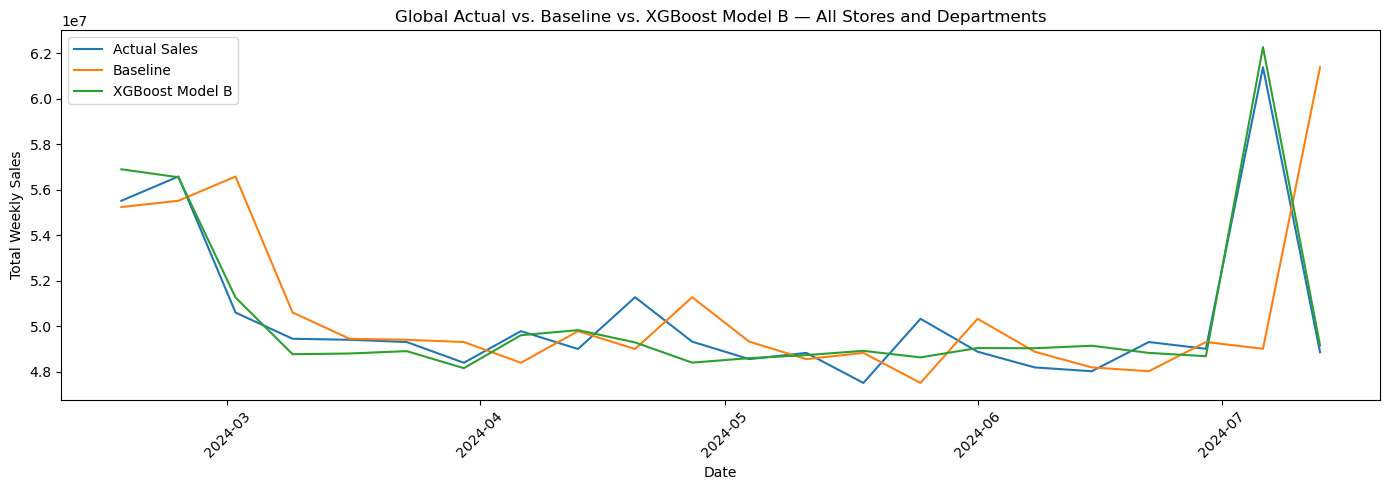

In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Train XGBoost Model B
model_B = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model_B.fit(X_train[features_A], y_train)

# Generate predictions
y_pred_B = model_B.predict(X_val[features_A])

# Evaluate model at the row level
mae = mean_absolute_error(y_val, y_pred_B)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_B))
global_mape = (
    np.abs((y_val - y_pred_B) / y_val.replace(0, np.nan))
).mean() * 100

print("Model B Validation MAE:", round(mae, 2))
print("Model B Validation RMSE:", round(rmse, 2))
print("Model B Validation MAPE:", round(global_mape, 2), "%")

# Compare global actual vs. predicted vs. baseline sales by date
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline_predicted": np.asarray(y_pred_baseline),
    "predicted": np.asarray(y_pred_B)
})

global_daily_sales = global_results.groupby("date")[
    ["actual", "baseline_predicted", "predicted"]
].sum().reset_index()

# Plot global actual vs. predicted sales
plt.figure(figsize=(14, 5))
plt.plot(global_daily_sales["date"], global_daily_sales["actual"], label="Actual Sales")
plt.plot(global_daily_sales["date"], global_daily_sales["baseline_predicted"], label="Baseline")
plt.plot(global_daily_sales["date"], global_daily_sales["predicted"], label="XGBoost Model B")

plt.title("Global Actual vs. Baseline vs. XGBoost Model B — All Stores and Departments")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Model C - XGBoost Historical + Seasonal + Store Features

In [ ]:
# ==========================================
# MODEL C — PREPARE DATA
# ==========================================

features_C = features_A + ["store_id", "department", "store_size"]

# Create separate datasets for Model C
X_train_C = train_data[features_C].copy()
X_val_C = val_data[features_C].copy()
X_test_C = test_data[features_C].copy()

# Convert categorical columns
for col in ["store_id", "department"]:
    X_train_C[col] = X_train_C[col].astype("category")
    X_val_C[col] = X_val_C[col].astype("category")
    X_test_C[col] = X_test_C[col].astype("category")

# Train Model C
model_C = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    enable_categorical=True
)

model_C.fit(X_train_C, y_train)

# Generate predictions
y_pred_C = model_C.predict(X_val_C)

In [27]:

# ==========================================
# COMPARE MODEL RESULTS
# ==========================================

models = {
    "Baseline": y_pred_baseline,
    "Model A - Linear Regression": y_pred,
    "Model B - XGBoost": y_pred_B,
    "Model C - XGBoost + Store/Department": y_pred_C
}

results = []

for name, predictions in models.items():
    actual = np.asarray(y_val)
    predictions = np.asarray(predictions)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "MAPE (%)": (
            np.abs(
                (actual - predictions)
                / np.where(actual == 0, np.nan, actual)
            ).mean() * 100
        )
    })

model_comparison = pd.DataFrame(results)

display(
    model_comparison.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "MAPE (%)": "{:.2f}%"
    }).set_properties(**{
        "min-width": "180px",
        "text-align": "right"
    })
)

,Model,MAE,RMSE,MAPE (%)
0,Baseline,"29,060.31","40,586.40",93.20%
1,Model A - Linear Regression,"22,281.05","29,639.10",77.91%
2,Model B - XGBoost,"21,929.00","29,209.95",78.15%
3,Model C - XGBoost + Store/Department,"21,448.84","28,383.44",75.56%


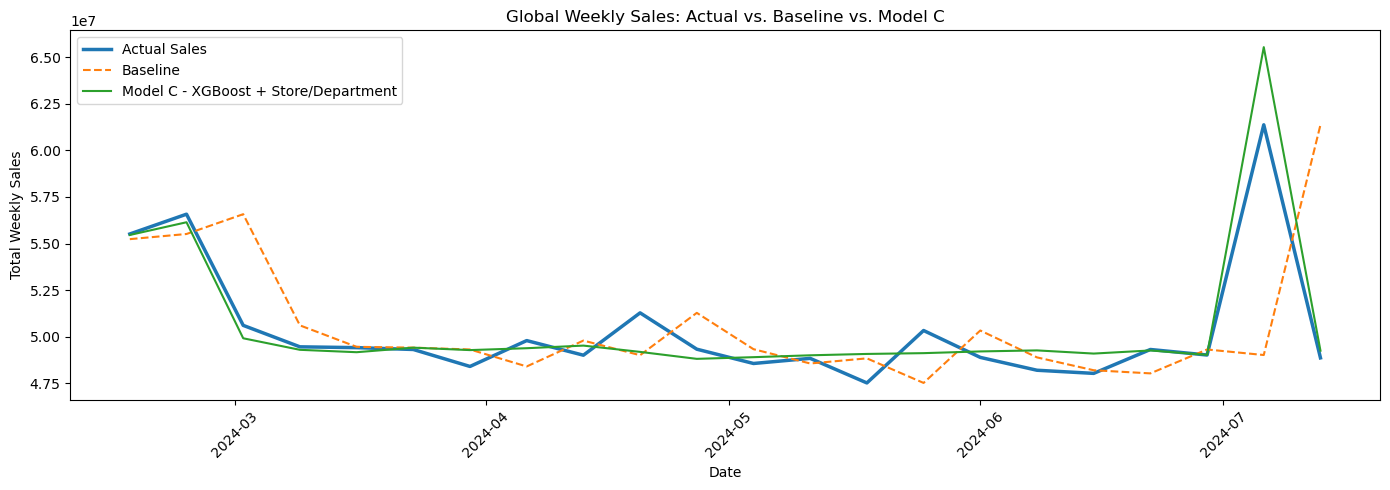

In [29]:

# Aggregate global weekly sales
global_results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline": np.asarray(y_pred_baseline),
    "model_C": np.asarray(y_pred_C)
})

global_weekly_sales = global_results.groupby("date", as_index=False)[
    ["actual", "baseline", "model_C"]
].sum()

# Plot comparison
plt.figure(figsize=(14, 5))

plt.plot(global_weekly_sales["date"], global_weekly_sales["actual"],
         label="Actual Sales", linewidth=2.5)
plt.plot(global_weekly_sales["date"], global_weekly_sales["baseline"],
         label="Baseline", linestyle="--")
plt.plot(global_weekly_sales["date"], global_weekly_sales["model_C"],
         label="Model C - XGBoost + Store/Department")

plt.title("Global Weekly Sales: Actual vs. Baseline vs. Model C")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Run on Test Set

Model C Test MAE: 26939.01
Model C Test RMSE: 37354.93
Model C Test MAPE: 77.11 %


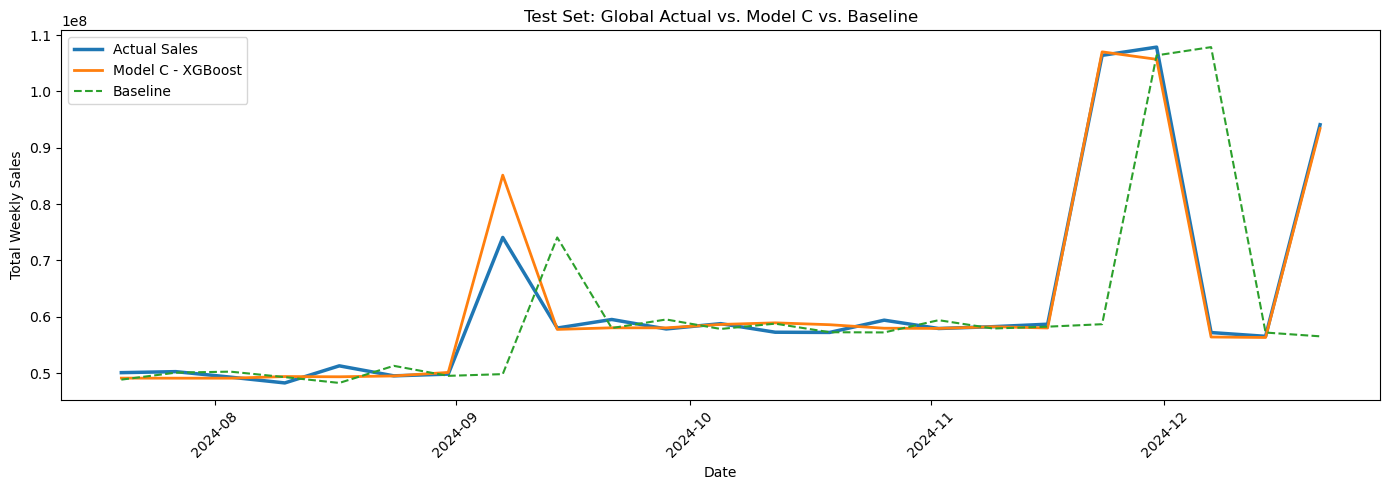

In [36]:

# ==========================================
# 1. PREDICT USING MODEL C
# ==========================================
y_pred_C_test = model_C.predict(X_test_C)

# ==========================================
# 2. GENERATE BASELINE PREDICTIONS
# ==========================================
y_pred_baseline_test = X_test_C["lag_1"].to_numpy()

# ==========================================
# 3. EVALUATE MODEL C
# ==========================================
mae_test = mean_absolute_error(y_test, y_pred_C_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_C_test))

actual = y_test.to_numpy()

mape_test = (
    np.abs((actual - y_pred_C_test) / np.where(actual == 0, np.nan, actual))
).mean() * 100

print("Model C Test MAE:", round(mae_test, 2))
print("Model C Test RMSE:", round(rmse_test, 2))
print("Model C Test MAPE:", round(mape_test, 2), "%")

# ==========================================
# 4. AGGREGATE GLOBAL WEEKLY SALES
# ==========================================
test_results = pd.DataFrame({
    "date": pd.to_datetime(test_data["date"]).to_numpy(),
    "actual": actual,
    "predicted": y_pred_C_test,
    "baseline": y_pred_baseline_test
})

global_test_sales = test_results.groupby("date", as_index=False)[
    ["actual", "predicted", "baseline"]
].sum()

# ==========================================
# 5. PLOT RESULTS
# ==========================================
plt.figure(figsize=(14, 5))

plt.plot(global_test_sales["date"], global_test_sales["actual"],
         label="Actual Sales", linewidth=2.5)

plt.plot(global_test_sales["date"], global_test_sales["predicted"],
         label="Model C - XGBoost", linewidth=2)

plt.plot(global_test_sales["date"], global_test_sales["baseline"],
         label="Baseline", linestyle="--")

plt.title("Test Set: Global Actual vs. Model C vs. Baseline")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Analysis of Model

In [31]:

# ==========================================
# MODEL RESULTS: ACTUAL VS. PREDICTED
# ==========================================

results = pd.DataFrame({
    "date": val_data["date"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": np.asarray(y_pred_C)  # Replace with model predictions
})

# Add month and week number
results["date"] = pd.to_datetime(results["date"])
results["Month"] = results["date"].dt.month
results["Week Number"] = results["date"].dt.isocalendar().week.astype(int)

# Aggregate global sales by week
results = results.groupby(
    ["Month", "Week Number"], as_index=False
)[["actual", "predicted"]].sum()

# Calculate percentage error
results["% Error"] = (
    (results["predicted"] - results["actual"])
    / results["actual"].replace(0, np.nan)
) * 100

# Rename columns
results = results.rename(columns={
    "actual": "Actual Sales",
    "predicted": "Predicted Sales"
})

# Display table
display(
    results.style.format({
        "Actual Sales": "{:,.2f}",
        "Predicted Sales": "{:,.2f}",
        "% Error": "{:+.2f}%"
    }).set_properties(**{
        "min-width": "140px",
        "text-align": "right"
    })
)


,Month,Week Number,Actual Sales,Predicted Sales,% Error
0,2,7,"55,511,143.56","55,458,128.00",-0.10%
1,2,8,"56,574,993.01","56,141,808.00",-0.77%
2,3,9,"50,601,429.92","49,908,032.00",-1.37%
3,3,10,"49,448,658.53","49,288,328.00",-0.32%
4,3,11,"49,404,919.29","49,159,452.00",-0.50%
5,3,12,"49,305,981.83","49,403,740.00",+0.20%
6,3,13,"48,394,172.98","49,272,848.00",+1.82%
7,4,14,"49,783,854.05","49,374,332.00",-0.82%
8,4,15,"48,998,891.31","49,514,484.00",+1.05%
9,4,16,"51,273,883.38","49,176,780.00",-4.09%


In [33]:
# Was there a correlation between economic values and weekly sales that the model didn't pickup? No visible correlation between economic factors and weekly sales
# Did the predicted sales struggle with store_type? Yes it did with predicted values resulting in > +/- 5%
# Did the predicted sales struggle with certain types of departments?

## Experiment Log Results

In [ ]:
import pandas as pd
import os

results_file = "model_experiment_log.csv"

# Load existing results or create a new log
if os.path.exists(results_file):
    experiment_log = pd.read_csv(results_file)
else:
    experiment_log = pd.DataFrame(columns=[
        "experiment_id",
        "model_name",
        "features",
        "MAE",
        "RMSE",
        "MAPE",
        "observations"
    ])

In [32]:
# ==========================================
# SAVE MODEL EXPERIMENT RESULTS
# ==========================================

from datetime import datetime
import os

results_file = r"C:\Users\paolo\OneDrive\Desktop\Data Science Projects\02_retail_sales_forecasting_SYN\model_expirment_results.csv"

experiments = [
    {
        "model_name": "Baseline",
        "features": ["lag_1"],
        "y_pred": y_pred_baseline
    },
    {
        "model_name": "Model A - Linear Regression",
        "features": features_A,
        "y_pred": y_pred
    },
    {
        "model_name": "Model B - XGBoost",
        "features": features_A,
        "y_pred": y_pred_B
    },
    {
        "model_name": "Model C - XGBoost + Store/Department",
        "features": features_C,
        "y_pred": y_pred_C
    }
]

# Load existing experiment log or create a new one
if os.path.exists(results_file):
    experiment_log = pd.read_csv(results_file)
else:
    experiment_log = pd.DataFrame(columns=[
        "experiment_id", "date_time", "model_name",
        "features", "MAE", "RMSE", "MAPE"
    ])

new_results = []
timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

for experiment in experiments:
    predictions = np.asarray(experiment["y_pred"])
    actual = np.asarray(y_val)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    actual_series = pd.Series(actual)
    mape = (
        np.abs(
            (actual_series - predictions)
            / actual_series.replace(0, np.nan)
        )
    ).mean() * 100

    new_results.append({
        "experiment_id": len(experiment_log) + len(new_results) + 1,
        "date_time": timestamp,
        "model_name": experiment["model_name"],
        "features": ", ".join(experiment["features"]),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE": round(mape, 2)
    })

# Append and save results
experiment_log = pd.concat(
    [experiment_log, pd.DataFrame(new_results)],
    ignore_index=True
)

experiment_log.to_csv(results_file, index=False)

print("Experiment results saved to:")
print(results_file)

display(experiment_log)

Experiment results saved to:
C:\Users\paolo\OneDrive\Desktop\Data Science Projects\02_retail_sales_forecasting_SYN\model_expirment_results.csv


,experiment_id,date_time,model_name,features,MAE,RMSE,MAPE
0,1,2026-11-02 18:20:02,Baseline,lag_1,29060.31,40586.40,93.20
1,2,2026-11-02 18:20:02,Model A - Linear Regression,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",22281.05,29639.10,77.91
2,3,2026-11-02 18:20:02,Model B - XGBoost,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",21929.00,29209.95,78.15
3,4,2026-11-02 19:02:18,Baseline,lag_1,29060.31,40586.40,93.20
4,5,2026-11-02 19:02:18,Model A - Linear Regression,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",22281.05,29639.10,77.91
5,6,2026-11-02 19:02:18,Model B - XGBoost,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",21929.00,29209.95,78.15
6,7,2026-11-02 19:02:18,Model C - XGBoost + Store/Department,"lag_1, lag_2, lag_4, lag_8, rolling_mean_2, ro...",21448.84,28383.44,75.56
